# Error by demand class (CA_1 / FOODS backtest)

The research question asks how AI forecasting compares with traditional methods **under volatile demand conditions**. This notebook breaks the Stage 3 backtest (`d_1914`–`d_1941`, model `m5-ca1-foods@1.1.0-bt`) down by demand class.

**Demand classes** (Syntetos–Boylan, computed by `mlengine.evaluation.demand_class` on each item's last 365 days before the backtest):

- **ADI** (average demand interval) = observed days / days with a sale.
- **CV²** = squared coefficient of variation of sales on days with a sale.
- Smooth: ADI < 1.32 and CV² < 0.49 · Erratic: ADI < 1.32 and CV² ≥ 0.49 · Intermittent: ADI ≥ 1.32 and CV² < 0.49 · Lumpy: ADI ≥ 1.32 and CV² ≥ 0.49.

All forecasts here are one step ahead (next day), exactly as in the README's Stage 3 numbers. The per-row predictions were stored by the model release, so this notebook needs no raw data or retraining.

In [1]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# The notebooks live in notebooks/; mlengine lives in the project root.
projectRoot = Path.cwd().resolve()
while not (projectRoot / "mlengine").is_dir() and projectRoot != projectRoot.parent:
    projectRoot = projectRoot.parent
sys.path.insert(0, str(projectRoot))
figuresDir = projectRoot / "reports" / "figures"
tablesDir = projectRoot / "reports" / "tables"
figuresDir.mkdir(parents=True, exist_ok=True)
tablesDir.mkdir(parents=True, exist_ok=True)

warnings.filterwarnings("ignore", category=DeprecationWarning)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

import mlengine
from mlengine import config
print(f"mlengine {mlengine.__version__} from {projectRoot}")

mlengine 0.1.0 from /home/karanei/SemProject_MLEngine


In [2]:
from mlengine.evaluation import metrics
from mlengine.models.artifact import ModelRegistry

artifact = ModelRegistry().get("m5-ca1-foods", "1.1.0-bt")
predictions = pd.read_parquet(artifact.path / "backtest" / "predictions.parquet")
perProduct = pd.read_parquet(artifact.path / "backtest" / "per_product.parquet")
predictions = predictions.merge(perProduct[["product_id", "demand_class", "adi", "cv2", "zeroShare"]], on="product_id")
print(f"Backtest rows: {len(predictions):,}; products: {predictions['product_id'].nunique():,}")
display(perProduct["demand_class"].value_counts().rename("products").to_frame())

Backtest rows: 40,236; products: 1,437


,products
demand_class,
INTERMITTENT,925
LUMPY,249
SMOOTH,221
ERRATIC,37
INSUFFICIENT_DATA,5


In [3]:
classOrder = ["SMOOTH", "ERRATIC", "INTERMITTENT", "LUMPY", "INSUFFICIENT_DATA"]
methods = {"AI": "ai", "Naive": "naive_last_value", "Seasonal naive": "seasonal_naive_7"}
rows = []
for demandClass in classOrder:
    group = predictions[predictions["demand_class"] == demandClass]
    if group.empty:
        continue
    row = {"demand_class": demandClass, "products": group["product_id"].nunique(),
           "mean_daily_units": group["actual"].mean(), "zero_share": (group["actual"] == 0).mean()}
    for label, column in methods.items():
        summary = metrics.summary(group["actual"], group[column])
        row[f"{label} RMSE"], row[f"{label} MAE"], row[f"{label} WAPE"] = summary["rmse"], summary["mae"], summary["wape"]
    row["AI RMSE gain vs naive"] = 1 - row["AI RMSE"] / row["Naive RMSE"]
    row["AI MAE gain vs naive"] = 1 - row["AI MAE"] / row["Naive MAE"]
    rows.append(row)
byClass = pd.DataFrame(rows).set_index("demand_class")
display(byClass[["products", "mean_daily_units", "zero_share", "AI RMSE", "Naive RMSE", "Seasonal naive RMSE",
                 "AI MAE", "Naive MAE", "AI WAPE", "Naive WAPE", "AI RMSE gain vs naive", "AI MAE gain vs naive"]])
byClass.to_csv(tablesDir / "backtest_error_by_demand_class.csv")

,products,mean_daily_units,zero_share,AI RMSE,Naive RMSE,Seasonal naive RMSE,AI MAE,Naive MAE,AI WAPE,Naive WAPE,AI RMSE gain vs naive,AI MAE gain vs naive
demand_class,,,,,,,,,,,,
SMOOTH,221,6.045,0.111,3.725,5.215,5.001,2.423,3.285,0.401,0.543,0.286,0.262
ERRATIC,37,5.854,0.142,5.156,6.555,6.651,2.992,3.847,0.511,0.657,0.213,0.222
INTERMITTENT,925,1.355,0.481,1.583,2.115,2.209,1.035,1.249,0.764,0.922,0.252,0.172
LUMPY,249,1.739,0.460,2.643,3.542,3.366,1.485,1.822,0.854,1.048,0.254,0.185
INSUFFICIENT_DATA,5,1.143,0.657,1.690,2.204,2.315,1.012,1.214,0.885,1.062,0.233,0.167


### How often does the AI model beat naive on an individual product?

Store-level numbers can hide products where the simple method wins. For each product, compare 28-day MAE and RMSE.

In [4]:
perProduct["ai_beats_naive_mae"] = perProduct["ai_mae"] < perProduct["naive_last_value_mae"]
perProduct["ai_beats_naive_rmse"] = perProduct["ai_rmse"] < perProduct["naive_last_value_rmse"]
winRates = perProduct.groupby("demand_class")[["ai_beats_naive_mae", "ai_beats_naive_rmse"]].mean().reindex(classOrder).dropna()
winRates.loc["ALL"] = perProduct[["ai_beats_naive_mae", "ai_beats_naive_rmse"]].mean()
display((100 * winRates).round(1).rename(columns={"ai_beats_naive_mae": "% products AI wins on MAE",
                                                  "ai_beats_naive_rmse": "% products AI wins on RMSE"}))

,% products AI wins on MAE,% products AI wins on RMSE
demand_class,,
SMOOTH,95.500,96.800
ERRATIC,100.000,100.000
INTERMITTENT,73.800,96.400
LUMPY,77.900,93.600
INSUFFICIENT_DATA,80.000,80.000
ALL,78.600,96.000


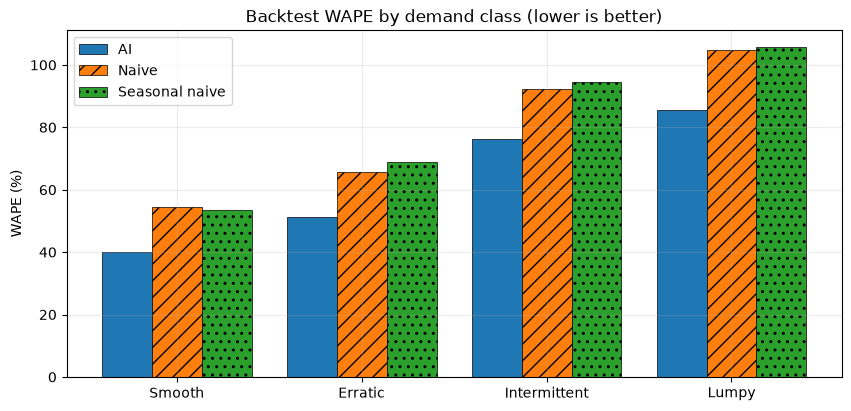

In [5]:
figure, axis = plt.subplots(figsize=(10, 4.5))
plotted = byClass.loc[[c for c in classOrder[:4] if c in byClass.index]]
positions = np.arange(len(plotted))
width = 0.27
hatches = {"AI": "", "Naive": "//", "Seasonal naive": ".."}
for offset, label in zip([-width, 0, width], methods):
    axis.bar(positions + offset, plotted[f"{label} WAPE"] * 100, width, label=label, hatch=hatches[label],
             edgecolor="black", linewidth=0.5)
axis.set_xticks(positions, [c.title() for c in plotted.index])
axis.set_ylabel("WAPE (%)")
axis.set_title("Backtest WAPE by demand class (lower is better)")
axis.legend()
figure.savefig(figuresDir / "backtest_wape_by_demand_class.png", dpi=120, bbox_inches="tight")
plt.show()

## Conclusions

| Demand class | Products | Mean units/day | AI RMSE | Naive RMSE | AI gain (RMSE / MAE) | Products where AI wins (MAE / RMSE) |
| --- | --- | --- | --- | --- | --- | --- |
| Smooth | 221 | 6.0 | 3.73 | 5.22 | 29% / 26% | 96% / 97% |
| Erratic | 37 | 5.9 | 5.16 | 6.56 | 21% / 22% | 100% / 100% |
| Intermittent | 925 | 1.4 | 1.58 | 2.12 | 25% / 17% | 74% / 96% |
| Lumpy | 249 | 1.7 | 2.64 | 3.54 | 25% / 19% | 78% / 94% |

- **The AI model beats the naive baseline in every demand class**, including the volatile ones (erratic, lumpy). Its RMSE advantage is roughly constant at 21–29%. This is the direct answer to the research question for this store: the gain does not disappear under volatile demand.
- **The MAE advantage is smaller for intermittent and lumpy products (17–19%) than for smooth ones (26%)**, and on MAE the naive forecast still wins for about a quarter of the intermittent and lumpy items. This is the same effect seen in the small-store simulation: Tweedie predicts the expected value, and for items that often sell zero, a persistence forecast can have a lower *absolute* error. On RMSE the AI model wins for 94–97% of items in every class.
- **Relative error (WAPE) is much higher for intermittent and lumpy items** (76–85%, against 40% for smooth), for every method. These products are inherently harder to forecast, and the app should say so next to the forecast (design §8.10: the demand-class summary card).
- **Most of this store's FOODS items are intermittent** (925 of 1,437). FOODS is the densest M5 category, so HOUSEHOLD and HOBBIES would be more intermittent still.
- Caveat: one store, a 28-day window and one-step-ahead forecasts. Per-product numbers rest on only 28 days each, so the app labels them as a small sample.
